In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import matplotlib.pyplot as plt
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

miktex_bin = r"C:\Users\gkova\AppData\Local\Programs\MiKTeX\miktex\bin\x64"

if miktex_bin not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + miktex_bin
import shutil
# This check MUST return True for usetex to work
print(f"LaTeX found: {shutil.which('latex') is not None}")
# df = pd.read_csv("benchmark_comparison_results.csv", sep=";")
# df = pd.read_csv("./benchmark_comparison_results_new/results_tube_geo.csv", sep=";")
# df = pd.read_csv("./benchmark_comparison_results_new/results_tube_prop.csv", sep=";")
df = pd.read_csv("./benchmark_comparison_results_new/results_tube_bc.csv", sep=";")
df = df.sort_values(
    by="case_path",
    key=lambda col: col.str.lower()
)
df.head()

LaTeX found: True


,case_path,nm_mean,nm_std,baseline_mean,baseline_std,err_inf,err_l1,err_l2,denom_inf,denom_l1,denom_l2,bound
0,../../../CFDBench/tube/bc\case0001,0.096827,0.114634,0.097622,0.117013,[[0.08210551 0.01063544 0.0076378 ... 0.00554...,[[0.08666951 0.01077586 0.00769576 ... 0.00554...,[[0.08223226 0.01063637 0.00763802 ... 0.00554...,[[0.08210551 0.01063544 0.0076378 ... 0.00554...,[[0.08210551 0.01063544 0.0076378 ... 0.00554...,[[0.08210551 0.01063544 0.0076378 ... 0.00554...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....
1,../../../CFDBench/tube/bc\case0002,0.145301,0.171782,0.146429,0.175219,[[0.1241415 0.01701262 0.01253051 ... 0.00871...,[[0.13095913 0.01722262 0.01262356 ... 0.00872...,[[0.12432856 0.01701392 0.01253086 ... 0.00871...,[[0.1241415 0.01701262 0.01253051 ... 0.00871...,[[0.1241415 0.01701262 0.01253051 ... 0.00871...,[[0.1241415 0.01701262 0.01253051 ... 0.00871...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....
2,../../../CFDBench/tube/bc\case0003,0.193783,0.228790,0.195235,0.233245,[[0.16671598 0.02383245 0.01803339 ... 0.01191...,[[0.17577203 0.02411439 0.01815871 ... 0.01191...,[[0.16696176 0.02383412 0.01803383 ... 0.01191...,[[0.16671598 0.02383245 0.01803339 ... 0.01191...,[[0.16671598 0.02383245 0.01803339 ... 0.01191...,[[0.16671598 0.02383245 0.01803339 ... 0.01191...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....
3,../../../CFDBench/tube/bc\case0004,0.242262,0.285652,0.244037,0.291323,[[0.20978234 0.03097663 0.02383139 ... 0.01403...,[[0.2210611 0.03134411 0.02398156 ... 0.01403...,[[0.21008532 0.03097881 0.02383187 ... 0.01403...,[[0.20978234 0.03097663 0.02383139 ... 0.01403...,[[0.20978234 0.03097663 0.02383139 ... 0.01403...,[[0.20978234 0.03097663 0.02383139 ... 0.01403...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....
4,../../../CFDBench/tube/bc\case0005,0.290731,0.342363,0.292839,0.349033,[[0.2532737 0.03849003 0.0300104 ... 0.01709...,[[0.2667614 0.03895085 0.03018155 ... 0.01709...,[[0.25363258 0.03849279 0.03001089 ... 0.01709...,[[0.2532737 0.03849003 0.0300104 ... 0.01709...,[[0.2532737 0.03849003 0.0300104 ... 0.01709...,[[0.2532737 0.03849003 0.0300104 ... 0.01709...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....


In [35]:
errors_l1 = []
errors_l2 = []
errors_inf = []

case_nums = []

reynolds = []

for i, row in df.iterrows():
    case_num = int(row["case_path"].split("case")[-1])
    case_path = os.path.join("./benchmark_comparison_results_new", str(case_num))


    err_inf = np.load(os.path.join(case_path, "err_inf.npy"))
    err_l1 = np.load(os.path.join(case_path, "err_l1.npy"))
    err_l2 = np.load(os.path.join(case_path, "err_l2.npy"))

    denom_inf = np.load(os.path.join(case_path, "denom_inf.npy"))
    denom_l1 = np.load(os.path.join(case_path, "denom_l1.npy"))
    denom_l2 = np.load(os.path.join(case_path, "denom_l2.npy"))

    bound = np.load(os.path.join(case_path, "bound.npy"))

    if err_inf.max() > 1000:
        continue

    case_nums.append(case_num)
    
    errors_l1.append(err_l1[bound != 1].sum() / denom_l1[bound != 1].sum())
    errors_l2.append(err_l2[bound != 1].sum() / denom_l2[bound != 1].sum())
    errors_inf.append(err_inf[bound != 1].sum() / denom_inf[bound != 1].sum())

    with open(os.path.join(row["case_path"], "case.json")) as f:
        props = json.load(f)

    # Re = (props["density"] * props["vel_in"] * props["height"]) / props["viscosity"]
    # reynolds.append(Re)

errors_l1 = np.array(errors_l1)
errors_l2 = np.array(errors_l2)
errors_inf = np.array(errors_inf)
case_nums = np.array(case_nums)

print(f"l1 = {errors_l1.mean()} +- {errors_l1.std()}")
print(f"l2 = {errors_l2.mean()} +- {errors_l2.std()}")
print(f"inf = {errors_inf.mean()} +- {errors_inf.std()}")

l1 = 0.08656112785694162 +- 0.10378361256219729
l2 = 0.07444556838269654 +- 0.08215768309840404
inf = 0.07071475776225106 +- 0.075248828920909


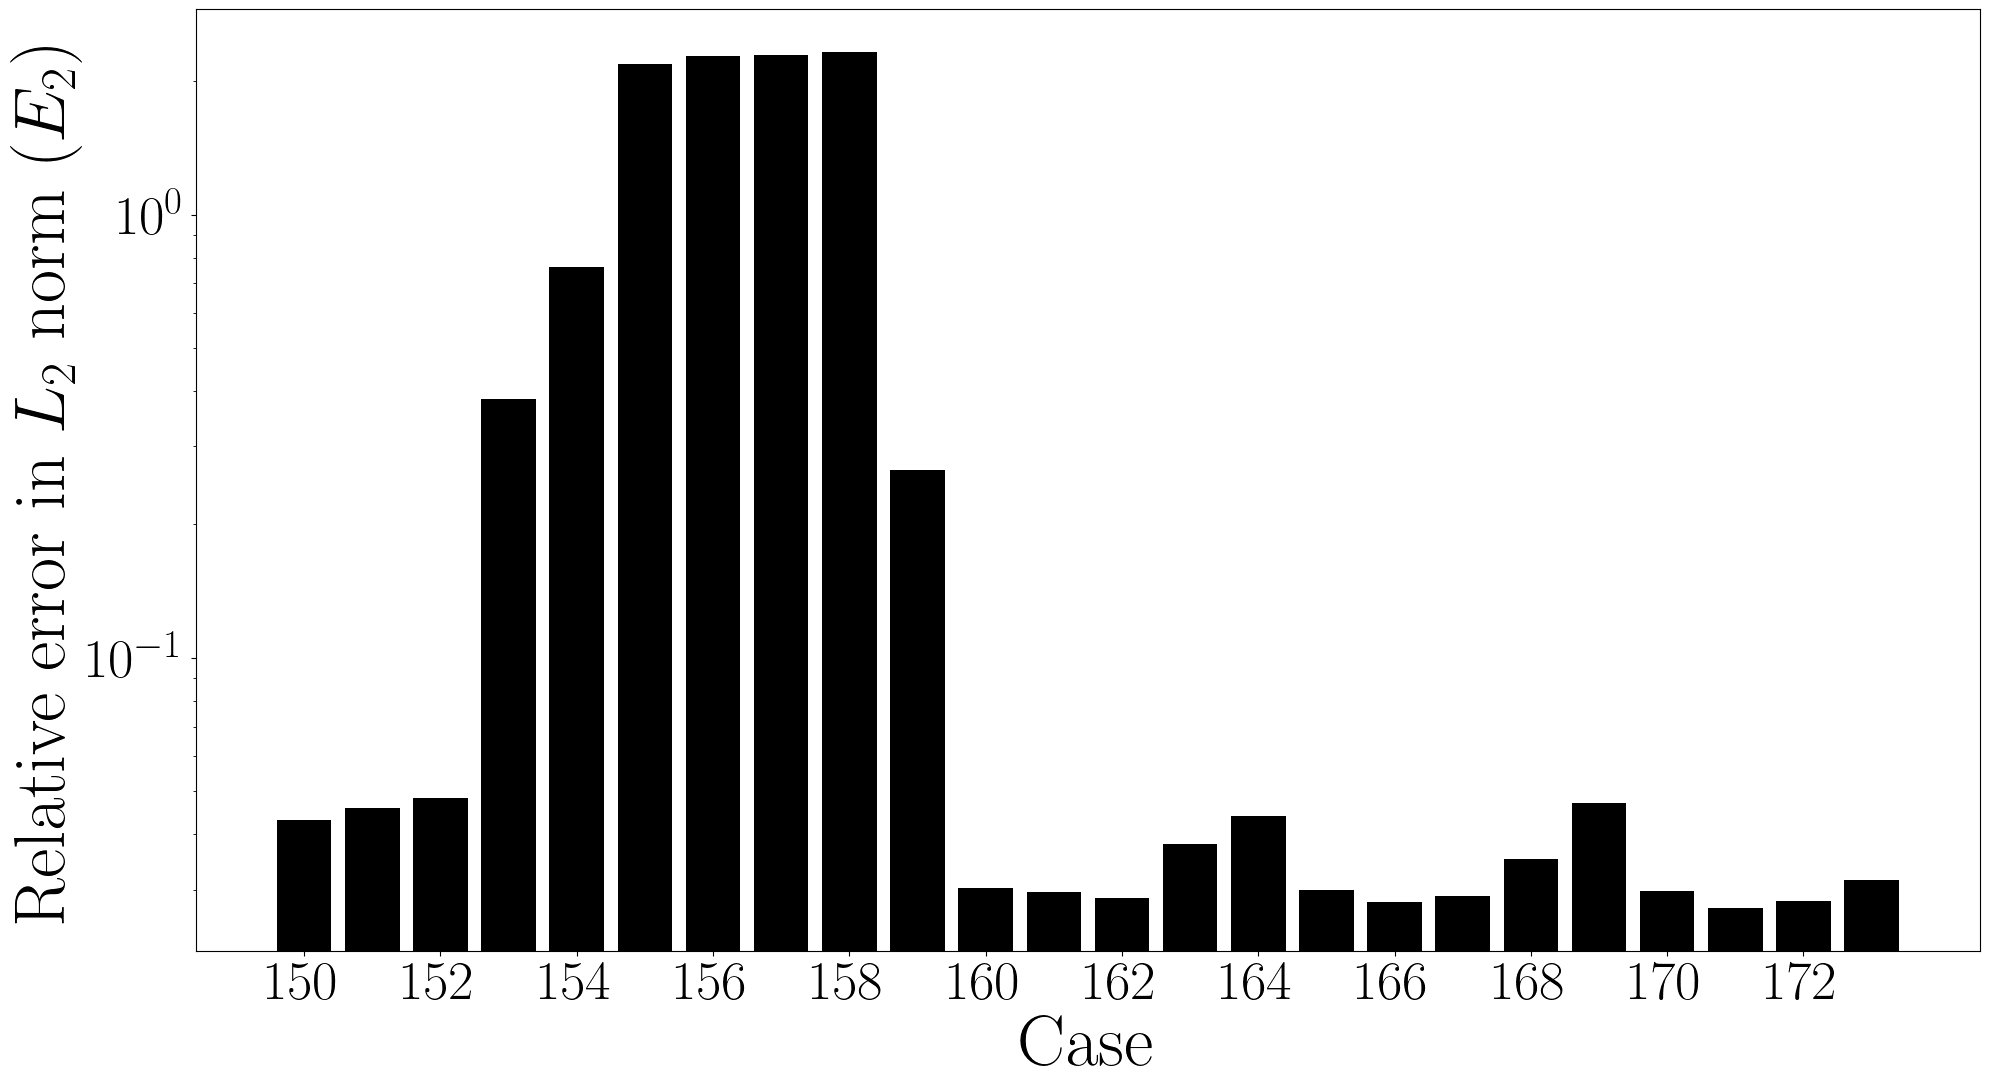

In [20]:
fig, ax = plt.subplots(figsize=(20, 11))

ax.bar(case_nums, errors_l2, color="black")

# ax.set_xticks(case_nums)
ax.set_xticks(case_nums[::2])

ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel("Case", fontsize=52)
ax.set_ylabel(r"Relative error in $L_2$ norm ($E_2$)", fontsize=52)

plt.tight_layout()

plt.savefig("err_tube_geo.pdf")
# plt.savefig("err_tube_prop.pdf")
# plt.savefig("err_tube_bc.pdf")

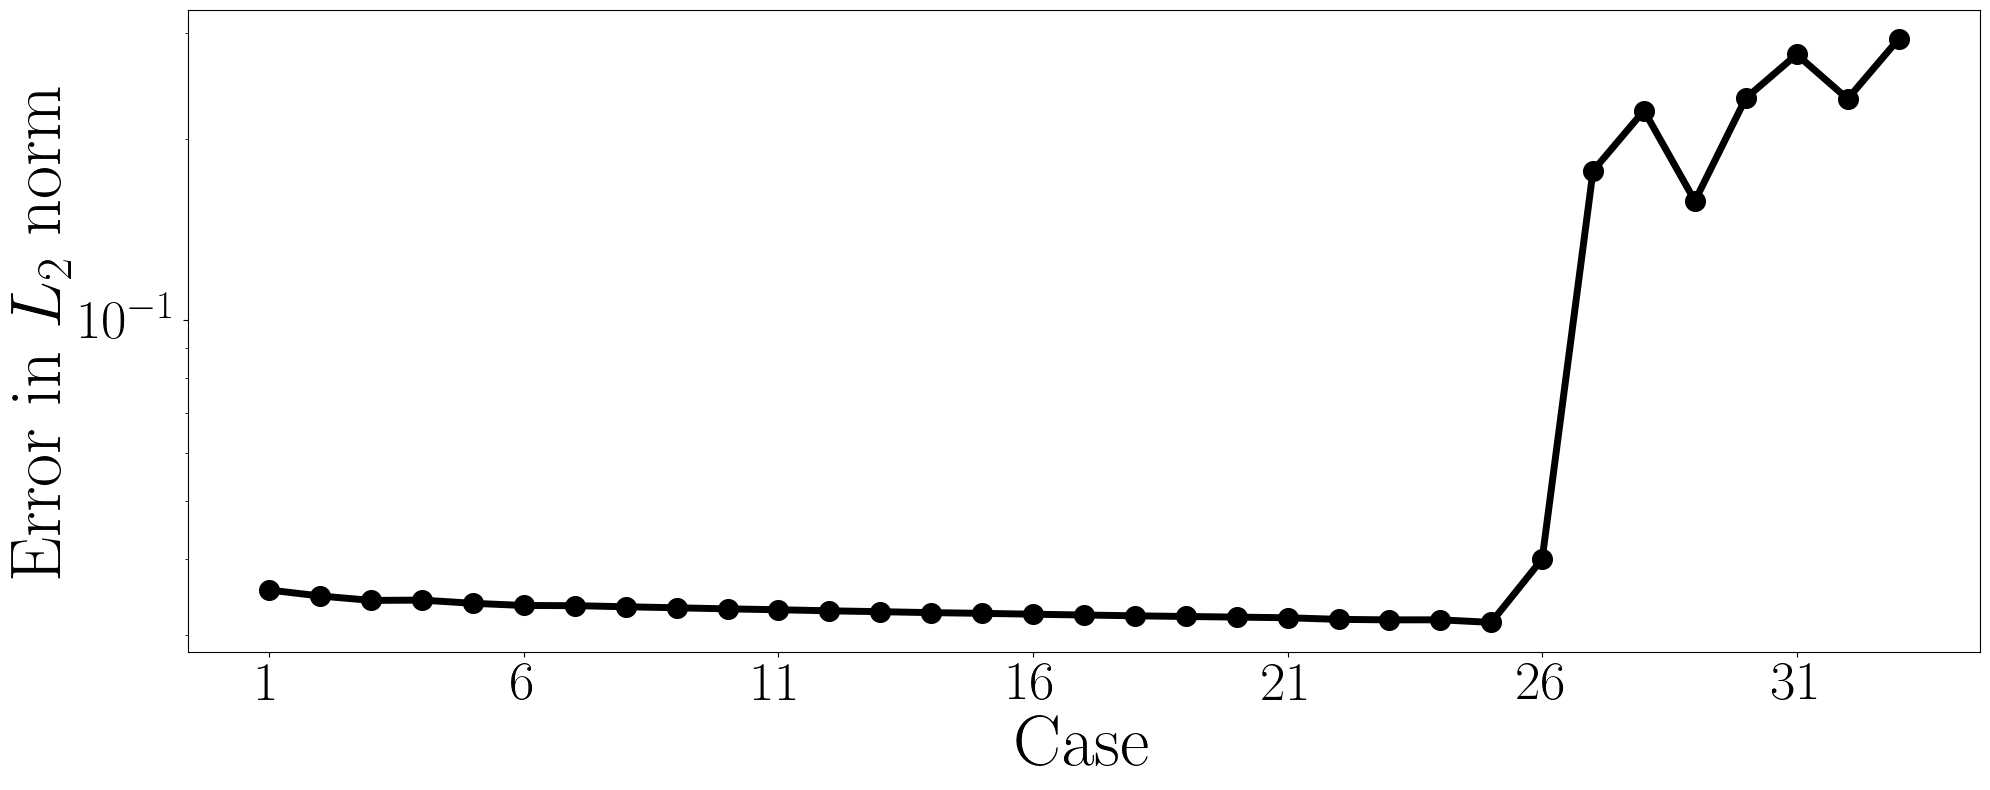

In [36]:
fig, ax = plt.subplots(figsize=(20, 8))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, errors_l2, color="black", linewidth=5)
ax.scatter(case_nums, errors_l2, color="black", s=200)

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::5])

ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel("Case", fontsize=52)
ax.set_ylabel(r"Error in $L_2$ norm", fontsize=52)

plt.tight_layout()

# plt.savefig("err_tube_geo.pdf")
# plt.savefig("err_tube_prop.pdf")
plt.savefig("err_tube_bc.pdf")

In [5]:
print(f"{errors_l2.mean()} +- {errors_l2.std()}")

0.22281855801221895 +- 0.22380690469657027


In [ ]:
indexed_values = list(zip(case_nums, errors_l2))

sorted_errors = sorted(indexed_values, key=lambda item: item[1], reverse=True)

for row in sorted_errors:
    print(f"{row[0]} -> {row[1]}")

In [ ]:
# case_path = os.path.join("./benchmark_comparison_results_new/", str(154), "err_l2.npy")
# case_path = "../../../CFDBench/tube/prop/case0065/u.npy"
case_path = os.path.join("./benchmark_comparison_results_new/cylinder", str(1), "err_l2.npy")
err = np.load(case_path)

bound = np.load(os.path.join("./benchmark_comparison_results_new/cylinder", str(1), "bound.npy"))

fig, ax = plt.subplots(1, 2, figsize=(12, 8))

ax[0].imshow(err * (1 - bound))

case_path = "../../../CFDBench/cylinder/bc/case0001/u.npy"
err = np.load(case_path)

ax[1].imshow(err[-1])

ax[0].axis("off")
ax[1].axis("off")

ax[0].set_title("Case 161", fontsize=24)
ax[1].set_title("Case 156", fontsize=24)

plt.tight_layout()

f# plt.savefig("geom_faulty.pdf")

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

plt.scatter(reynolds, errors_l2, color="black")

for i, (x, y) in enumerate(zip(reynolds, errors_l2)):
    if case_nums[i] % 10 == 0:
        plt.text(x, y, str(case_nums[i]), fontsize=20, ha='right', va='bottom')

ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_xlabel("Reynolds number", fontsize=24)
ax.set_ylabel(r"Relative error in $L_2$ norm", fontsize=24)

plt.savefig("prop_reynolds.pdf")

In [ ]:
# case_path = os.path.join("./benchmark_comparison_results_new/", str(154), "err_l2.npy")
# case_path = "../../../CFDBench/tube/prop/case0065/u.npy"
case_path = os.path.join("./benchmark_comparison_results_new/cylinder", str(0), "err_l2.npy")
err = np.load(case_path)

fig, ax = plt.subplots(1, 2, figsize=(12, 8))

im = ax[0].imshow(err)

case_path = "../../../CFDBench/tube/prop/case0061/u.npy"
err = np.load(case_path)

ax[1].imshow(err[-1])

ax[0].axis("off")
ax[1].axis("off")

ax[0].set_title("Case 161", fontsize=24)
ax[1].set_title("Case 156", fontsize=24)

plt.colorbar(im)

plt.tight_layout()

# plt.savefig("geom_faulty.pdf")